# Demo D3.2 · Inside the algorithms — k-means step by step, dendrograms, and how a tree chooses a split
**Horizon Gulf Bank · Project MIZAN** · CAIP AIP-210 · Certified AI Practitioner · Day 3 · ⏱ 35 min · **Demo · complete solution**

Open the black box on three Day 3 algorithms with small, visual examples drawn from HGB data.

### Scenario
**Horizon Gulf Bank (HGB)** is a fictional UAE retail bank with 250,000 customers. Its Board approved **Project MIZAN** — an AI decisioning platform covering credit, fraud, collateral valuation, cash logistics, customer retention and document automation. You are a junior ML practitioner in the MIZAN squad.

Marketing wants customer segments; Fraud wants interpretable rules. Before the labs, learners must *see* how k-means moves centroids and how a decision tree uses Gini impurity to pick its first question.

In [1]:
# ── Project MIZAN course setup ─ run this cell first ──────────────────────────
from pathlib import Path
import warnings, time
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Locate the course root (the folder that contains data/generate_data.py) from wherever this notebook lives
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "generate_data.py").exists())
DATA = ROOT / "data"          # raw synthetic datasets (read-only)
CKPT = ROOT / "checkpoints"   # hand-off artefacts between labs (lets you start any lab fresh)
CKPT.mkdir(exist_ok=True)
pd.set_option("display.max_columns", 60); pd.set_option("display.width", 160)
plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.grid": True, "grid.alpha": .3})
RNG = 42
print("Course root:", ROOT)

Course root: C:\Users\Pushkar\Downloads\CAIP-AIP210-FINANCIAL-SERVICES-TRAINER-PACK\CAIP-AIP210-TopTier-Courseware


## 1 · k-means by hand — watch the centroids move

Two features, 3,000 customers, k=4. Each iteration: assign every point to its nearest centroid, then move each centroid to the mean of its points. The **inertia** (within-cluster sum of squares) can only go down.

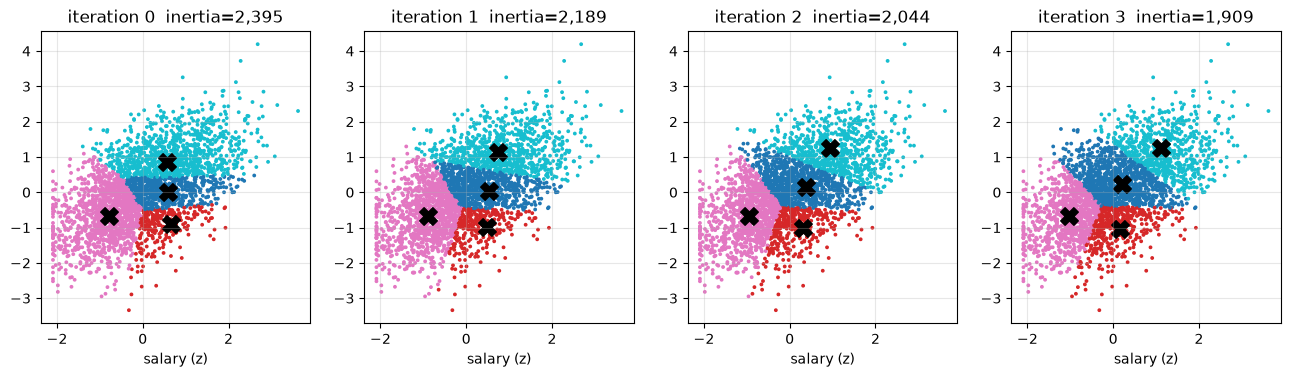

In [2]:
cust = pd.read_parquet(CKPT / "customers_clean.parquet")
pts = cust.sample(3000, random_state=RNG)
X2 = np.column_stack([np.log10(pts.monthly_salary_aed), np.log10(pts.avg_balance_aed + 100)])
X2 = (X2 - X2.mean(0)) / X2.std(0)
rng = np.random.default_rng(7); C = X2[rng.choice(len(X2), 4, replace=False)]
fig, axs = plt.subplots(1, 4, figsize=(16, 3.8))
for it, ax in zip(range(4), axs):
    lab = np.argmin(((X2[:, None, :] - C[None]) ** 2).sum(-1), axis=1)    # assign
    inertia = ((X2 - C[lab]) ** 2).sum()
    ax.scatter(*X2.T, c=lab, s=3, cmap="tab10"); ax.scatter(*C.T, c="k", marker="X", s=160)
    ax.set_title(f"iteration {it}  inertia={inertia:,.0f}"); ax.set_xlabel("salary (z)")
    C = np.array([X2[lab == k].mean(0) for k in range(4)])                 # update
plt.show()

## 2 · Choosing k: elbow vs silhouette

Inertia always falls as k grows, so look for the **elbow**. The **silhouette** (−1…1) measures how much closer each point is to its own cluster than to the next — higher is better.

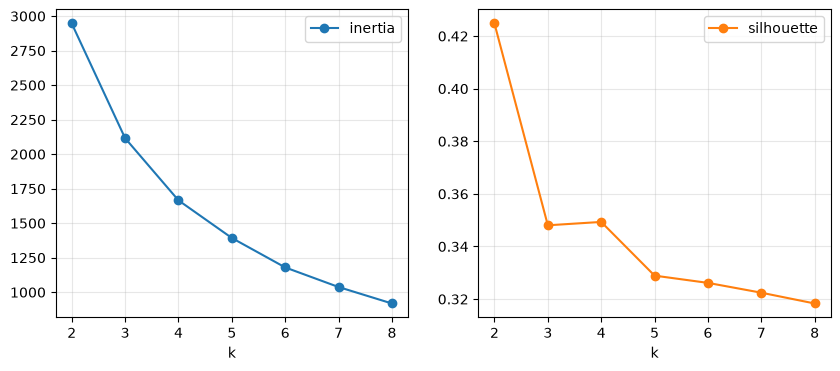

,inertia,silhouette
k,,
2,2946.576,0.425
3,2115.799,0.348
4,1665.309,0.349
5,1392.750,0.329
6,1179.499,0.326
7,1037.564,0.322
8,918.292,0.318


In [3]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
res = []
for k in range(2, 9):
    km = KMeans(n_clusters=k, n_init=5, random_state=RNG).fit(X2)
    res.append((k, km.inertia_, silhouette_score(X2, km.labels_)))
res = pd.DataFrame(res, columns=["k", "inertia", "silhouette"]).set_index("k")
res.plot(subplots=True, marker="o", figsize=(10, 4), layout=(1, 2)); plt.show(); res.round(3)

## 3 · Hierarchical clustering and the dendrogram

Agglomerative clustering starts with every customer alone and repeatedly merges the closest pair. The **dendrogram** records the merges; cutting it horizontally gives any number of clusters — no k needed up front.

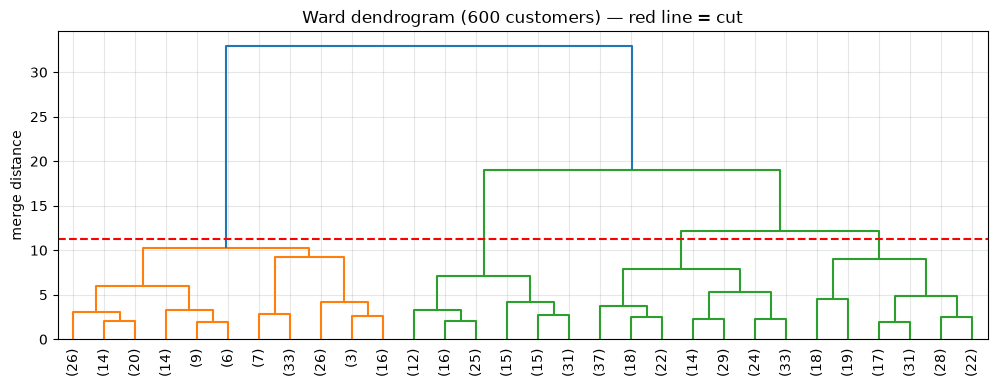

cut at 11.2 -> cluster sizes: [174 114 177 135]


In [4]:
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
Z = linkage(X2[:600], method="ward")
cut = (Z[-4, 2] + Z[-3, 2]) / 2                     # a height between the 3rd and 4th last merges -> 4 clusters
plt.figure(figsize=(12, 4)); dendrogram(Z, truncate_mode="lastp", p=30, leaf_rotation=90)
plt.axhline(cut, color="r", ls="--"); plt.title("Ward dendrogram (600 customers) — red line = cut"); plt.ylabel("merge distance"); plt.show()
print(f"cut at {cut:.1f} -> cluster sizes:", np.bincount(fcluster(Z, t=cut, criterion="distance"))[1:])

## 4 · How a decision tree picks its first split — Gini by hand

A tree asks the question that makes the children **purest**. Gini impurity = 1 − Σp². We compute the impurity reduction for every threshold on `aecb_score`, find the best, and check that scikit-learn’s root node agrees.

root Gini = 0.1280 | root entropy = 0.3611


best hand-computed split: aecb_score <= 625 (Gini decrease 0.00783)


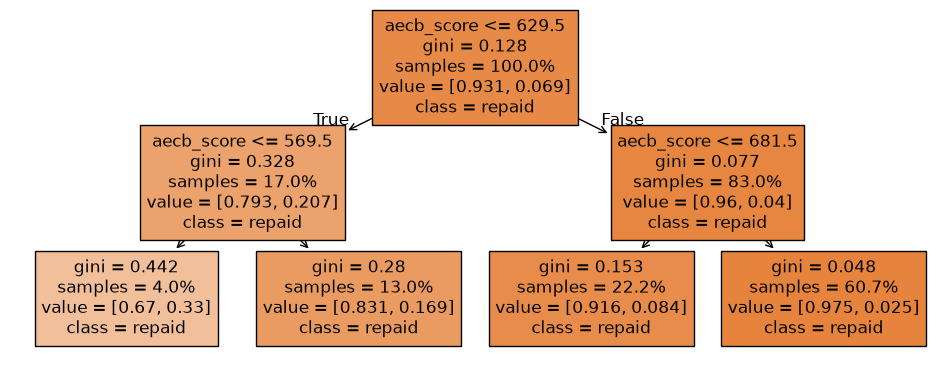

In [5]:
from sklearn.tree import DecisionTreeClassifier, plot_tree
loans = pd.read_csv(DATA / "loan_applications.csv", usecols=["aecb_score", "debt_burden_ratio", "default_12m"]).dropna()
gini = lambda y: 1 - ((np.bincount(y, minlength=2) / len(y)) ** 2).sum()
entropy = lambda y: -sum(p * np.log2(p) for p in np.bincount(y, minlength=2) / len(y) if p > 0)
y = loans.default_12m.to_numpy(); x = loans.aecb_score.to_numpy()
print(f"root Gini = {gini(y):.4f} | root entropy = {entropy(y):.4f}")
best = max(((t, gini(y) - ((x <= t).mean() * gini(y[x <= t]) + (x > t).mean() * gini(y[x > t]))) for t in np.arange(500, 850, 5)), key=lambda r: r[1])
print(f"best hand-computed split: aecb_score <= {best[0]} (Gini decrease {best[1]:.5f})")
tree = DecisionTreeClassifier(max_depth=2, random_state=RNG).fit(loans[["aecb_score", "debt_burden_ratio"]], y)
plt.figure(figsize=(12, 4.5)); plot_tree(tree, feature_names=["aecb_score", "debt_burden_ratio"], class_names=["repaid", "default"], filled=True, proportion=True); plt.show()